In [2]:
import sys
import os
import numpy as np

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from utils.libanaly import Plot_Background, CircleCalc
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from scipy.ndimage import zoom
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter
import scipy.stats as stats

In [3]:
plt.rcParams["text.usetex"] = True
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams[
    "text.latex.preamble"
] = r"""
\usepackage{amsmath}
\usepackage{amssymb}
"""
plt.rcParams["mathtext.fontset"] = "custom"
plt.rcParams["mathtext.rm"] = "Times New Roman"  # 设置正常文本的字体
plt.rcParams["mathtext.it"] = "Times New Roman:italic"  # 设置斜体文本的字体
plt.rcParams["mathtext.bf"] = "Times New Roman:bold"  # 设置粗体文本的字体

In [4]:
condition = np.load("../EHT-Imaging/data_out/condition.npy", allow_pickle=True)

In [5]:
def Plot_Background_NoNorm(
    fig,
    ax,
    array2d,
    xy_tick_labelsize=14,
    cbar_tick_labelsize=12,
    cbar_label_fontsize=16,
    cbar_label_pad=20,
    cbar_label_y=0.5,
    cbar_label_rotation=0,
    cbar_label_text="Value",  # Colorbar 标签文本
    data_vmin=None,  # 颜色映射的最小值 (None则自动)
    data_vmax=None,
    cmap="Greys_r",
    upscale_factor=1,
    phi0=False,
    condition=None,
    title="",
    title_fontsize=16,
    title_y=1.02,
    title_x=0.5,
    fmt=2,
    degree=False,
):  # 颜色映射的最大值 (None则自动)
    """
    绘制背景图，不进行数据归一化，并调整坐标轴和Colorbar的样式。

    参数:
    - fig: matplotlib Figure 对象
    - ax: matplotlib Axes 对象
    - array2d: 二维数组数据 (原始值)
    - xy_tick_labelsize: XY轴刻度数字的字号
    - cbar_tick_labelsize: Colorbar刻度数字的字号
    - cbar_label_fontsize: Colorbar标签的字号
    - cbar_label_pad: Colorbar标签与Colorbar之间的距离 (points)
    - cbar_label_y: Colorbar标签的相对垂直位置 (0.0-1.0, 0.5表示中间)
    - cbar_label_rotation: Colorbar标签的旋转角度
    - cbar_label_text: Colorbar的标签文本
    - data_vmin: pcolormesh的vmin参数 (None则自动确定)
    - data_vmax: pcolormesh的vmax参数 (None则自动确定)
    """

    if upscale_factor != 1:
        if phi0:
            array2d1 = np.cos(array2d)
            array2d2 = np.sin(array2d)
            array2d1 = zoom(array2d1, upscale_factor, order=1)
            array2d2 = zoom(array2d2, upscale_factor, order=1)
            array2d = np.arctan2(array2d2, array2d1)
        else:
            array2d = zoom(array2d, upscale_factor, order=1)  # 线性插值 (order=1)
    if condition is not None:
        condition = zoom(
            condition.astype(float), int(array2d.shape[0] / condition.shape[0]), order=0
        ).astype(bool)

    shape = array2d.shape[0]
    xgrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    ygrid = np.linspace(-16.3434, 16.3434, shape, endpoint=False)
    diff = np.diff(xgrid)[0] / 2.0
    xgrid += diff
    ygrid += diff
    xmesh, ymesh = np.meshgrid(xgrid, ygrid, indexing="ij")

    # 数据不再进行归一化

    bkg = ax.pcolormesh(
        xmesh,
        ymesh,
        array2d,  # 使用原始 array2d
        cmap=cmap,
        vmin=data_vmin,  # 使用新的 vmin 参数
        vmax=data_vmax,  # 使用新的 vmax 参数
        shading="auto",
    )

    ax.contour(xgrid, ygrid, condition, levels=[0.5], colors="grey")

    ax.set_aspect("equal")

    # 1. 调整XY轴刻度标签大小
    ax.set_xticks([-15, -10, -5, 0, 5, 10, 15])
    ax.set_yticks([-15, -10, -5, 0, 5, 10, 15])
    ax.tick_params(axis="x", labelsize=xy_tick_labelsize)
    ax.tick_params(axis="y", labelsize=xy_tick_labelsize)

    # 添加Colorbar
    clb = plt.colorbar(bkg, ax=ax, fraction=0.046, pad=0.05)

    # 2. 调整Colorbar刻度标签大小
    clb.ax.tick_params(labelsize=cbar_tick_labelsize)
    if degree:
        formatter = FuncFormatter(lambda x, pos: rf"${x:.{fmt}f}^\circ$")
        clb.ax.yaxis.set_major_formatter(formatter)
    # 3. 调整Colorbar标签的属性
    clb.set_label(
        cbar_label_text,  # 使用新的 cbar_label_text 参数
        labelpad=cbar_label_pad,
        y=cbar_label_y,
        rotation=cbar_label_rotation,
        size=cbar_label_fontsize,
    )

    ax.set_title(title, fontsize=title_fontsize, loc="center", pad=title_y, x=title_x)

    return bkg, clb

In [6]:
def vonmises_mean(d1evpaarr):
    # d1evpaarr is from -0.5pi to 0.5pi
    kappa_fit, mu_fit, _ = stats.vonmises.fit(d1evpaarr * 2)  # 只拟合 kappa 和 mu
    return mu_fit / 2

In [7]:
theta_mean = []
theta_std = []
P_mean = []
I_mean = []
theta_cor = []
badset = []
theta_data_vonmises_list = []
resolution = 64
xy_coord = [(i, j) for i in range(resolution) for j in range(resolution)]


num = 0
data_cor_list = []
for day in [95, 96, 100, 101]:
    with np.load(f"../EHT-Imaging/data_out/{day}.npz") as data:
        theta_mean.append(data["arr_0"])  # rad
        theta_std.append(data["arr_1"])  # rad
        P_mean.append(data["arr_2"] * 6.54737e12)  # ?这个哪来的
        I_mean.append(data["arr_3"] * 6.54737e12)

    All_data = np.load(f"../EHT-Imaging/data_out/{day}_all_data.npy")
    theta_data = 0.5 * np.arctan2(All_data[:, :, :, 2], All_data[:, :, :, 1])  # rad
    theta_data[np.isnan(theta_data)] = 0
    theta_vonmises_mean = np.apply_along_axis(vonmises_mean, 0, theta_data)
    theta_data_vonmises_list.append(
        CircleCalc.circle_sub_evpa(theta_data, theta_vonmises_mean)
        + theta_vonmises_mean
    )

    theta_data = (
        CircleCalc.circle_sub_evpa(theta_data, theta_mean[num]) + theta_mean[num]
    )
    # theta_data=theta_data*180./np.pi # degree

    data_cor = np.zeros((64 * 64, All_data.shape[0]))
    for x in range(len(xy_coord)):
        i, j = xy_coord[x]
        if (
            theta_mean[num][i][j] == 0
            and theta_std[num][i][j] == 0
            or np.isnan(theta_mean[num][i][j])
            or np.isnan(theta_std[num][i][j])
        ):
            badset.append(i * resolution + j)
        # data_cor[x] = (theta_data[i][j]-theta_mean[num][i][j])
        if np.isfinite(theta_mean[num][i][j]):
            pass
        data_cor[x] = CircleCalc.circle_sub_evpa(
            theta_data[:, i, j], theta_mean[num][i, j]
        )
    data_cor_list.append(data_cor)
    num += 1

# sum_of_pixels = topset_rank(data_cor_list, theta_std, condition)

for num in range(4):

    cor_data = np.dot(data_cor_list[num], data_cor_list[num].T) / All_data.shape[0]
    # cor_data = (
    #     np.dot(
    #         data_cor_list[num][:, np.argsort(sum_of_pixels)[:786]],
    #         data_cor_list[num][:, np.argsort(sum_of_pixels)[:786]].T,
    #     )
    #     / 786
    # )

    theta_cor.append(cor_data)

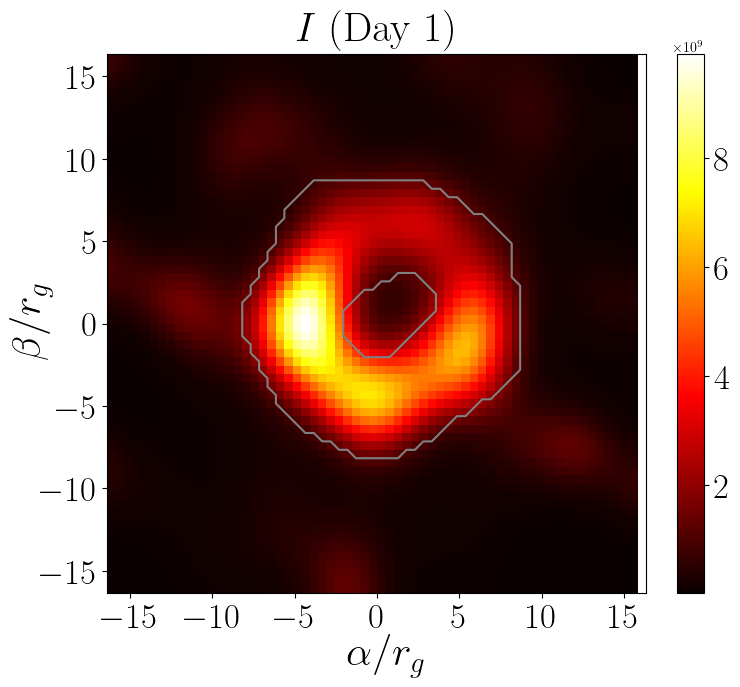

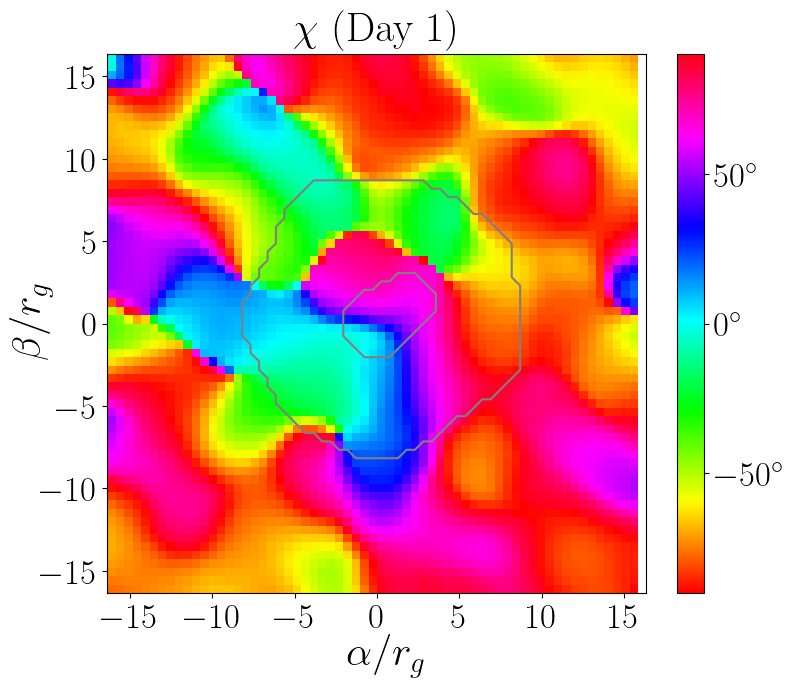

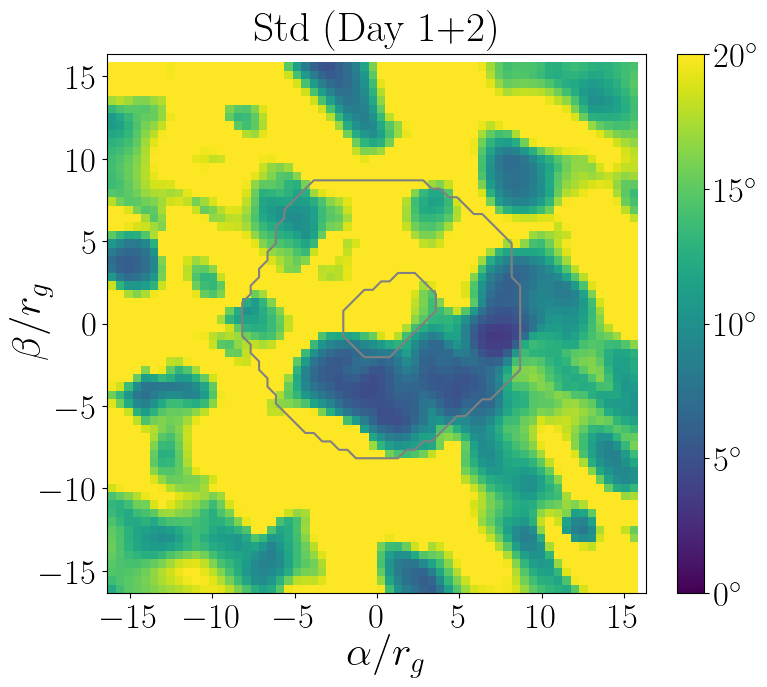

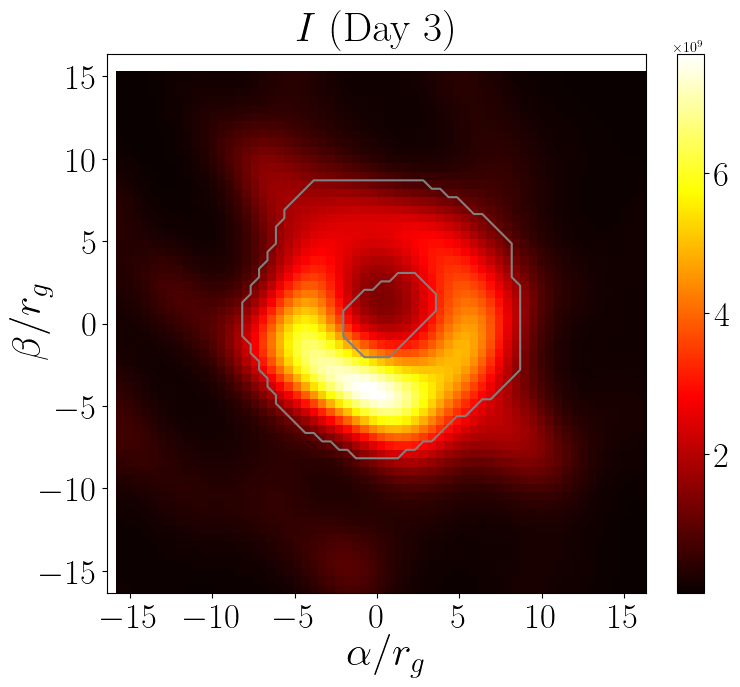

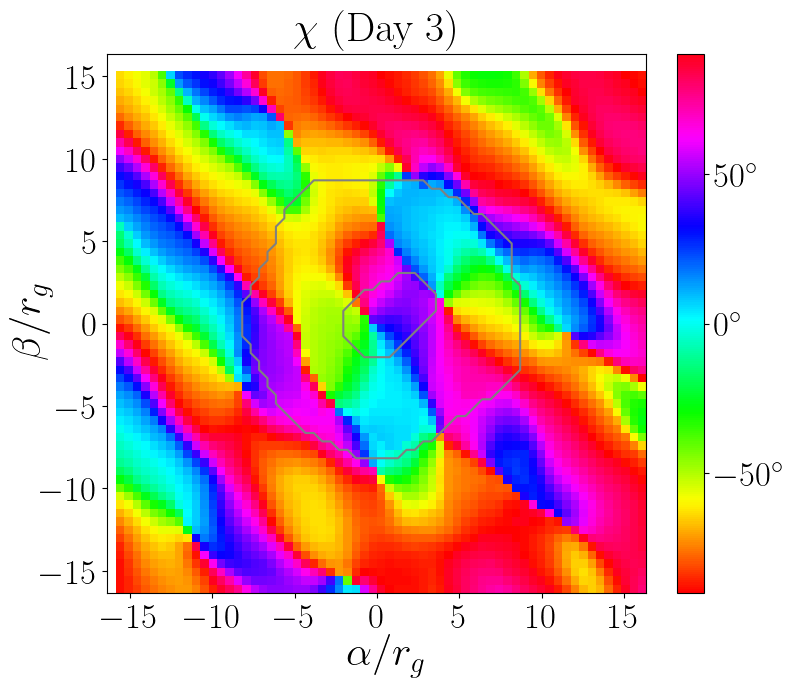

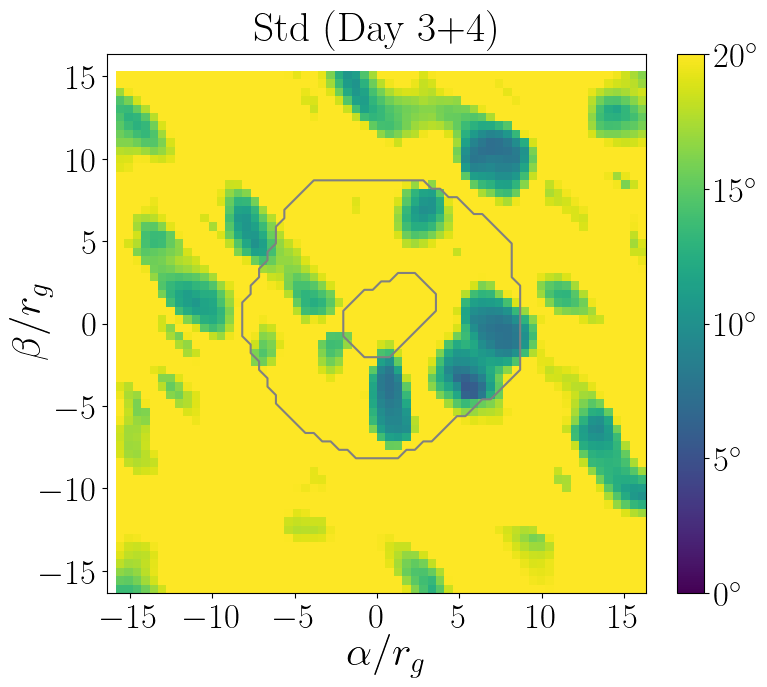

In [30]:
# Calculate combined std for 1+2 (95+96) and 3+4 (100+101)
std_12 = np.sqrt(theta_std[0] ** 2 + theta_std[1] ** 2)
std_34 = np.sqrt(theta_std[2] ** 2 + theta_std[3] ** 2)

# Plotting for Day 1 (95) and Day 3 (100)
days_indices = [0, 2]  # 0 for 95, 2 for 100
combined_stds = [std_12, std_34]
titles = ["Day 1+2", "Day 3+4"]
day = ["Day 1", "Day 3"]

for idx, day_idx in enumerate(days_indices):
    # Plot I
    fig, ax = plt.subplots(figsize=(8, 7))
    Plot_Background_NoNorm(
        fig,
        ax,
        I_mean[day_idx],
        xy_tick_labelsize=25,
        cbar_tick_labelsize=25,
        cbar_label_fontsize=20,
        cbar_label_pad=27,
        cbar_label_y=0.5,
        cbar_label_rotation=270,
        cbar_label_text=r"",  # 自定义Colorbar标签
        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
        # 或者您可以手动指定，例如:
        # data_vmin=0,
        # data_vmax=data_max_matrix[i, j],
        cmap="hot",
        upscale_factor=1,
        condition=condition,
        title=f"$I$ ({day[idx]})",
        title_fontsize=30,
        title_y=10,
        title_x=0.5,
        fmt=2,
    )
    fig.supxlabel(r"$\alpha/r_g$", fontsize=30, y=-0.01, x=0.50)
    fig.supylabel(r"$\beta/r_g$", fontsize=30, x=0.03, y=0.50)
    plt.show()

    # Plot EVPA
    fig, ax = plt.subplots(figsize=(8, 7))
    Plot_Background_NoNorm(
        fig,
        ax,
        theta_mean[day_idx] / np.pi * 180,
        xy_tick_labelsize=25,
        cbar_tick_labelsize=25,
        cbar_label_fontsize=20,
        cbar_label_pad=27,
        cbar_label_y=0.5,
        cbar_label_rotation=270,
        cbar_label_text=r"",  # 自定义Colorbar标签
        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
        # 或者您可以手动指定，例如:
        data_vmin=-90,
        data_vmax=90,
        cmap="hsv",
        upscale_factor=1,
        condition=condition,
        title=rf"$\chi$ ({day[idx]})",
        title_fontsize=30,
        title_y=10,
        title_x=0.5,
        fmt=0,
        degree=True,
    )
    fig.supxlabel(r"$\alpha/r_g$", fontsize=30, y=-0.01, x=0.50)
    fig.supylabel(r"$\beta/r_g$", fontsize=30, x=0.03, y=0.50)
    plt.show()

    # Plot Combined Std
    fig, ax = plt.subplots(figsize=(8, 7))
    Plot_Background_NoNorm(
        fig,
        ax,
        combined_stds[idx] / np.pi * 180,
        xy_tick_labelsize=25,
        cbar_tick_labelsize=25,
        cbar_label_fontsize=20,
        cbar_label_pad=27,
        cbar_label_y=0.5,
        cbar_label_rotation=270,
        cbar_label_text=r"",  # 自定义Colorbar标签
        # data_vmin 和 data_vmax 保持为 None，让pcolormesh自动确定范围
        # 或者您可以手动指定，例如:
        data_vmin=0,
        data_vmax=20,
        cmap="viridis",
        upscale_factor=1,
        condition=condition,
        title=f"Std ({titles[idx]})",
        title_fontsize=30,
        title_y=10,
        title_x=0.5,
        fmt=0,
        degree=True,
    )
    fig.supxlabel(r"$\alpha/r_g$", fontsize=30, y=-0.01, x=0.50)
    fig.supylabel(r"$\beta/r_g$", fontsize=30, x=0.03, y=0.50)
    plt.show()

In [9]:
cor_data[0].shape

(4096,)

<>:69: SyntaxWarning: invalid escape sequence '\m'
<>:69: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_512843/2291627326.py:69: SyntaxWarning: invalid escape sequence '\m'
  ax.set_ylabel('Covariance/$\mathrm{degree}^2$', fontsize=label_size) # 纵坐标名字


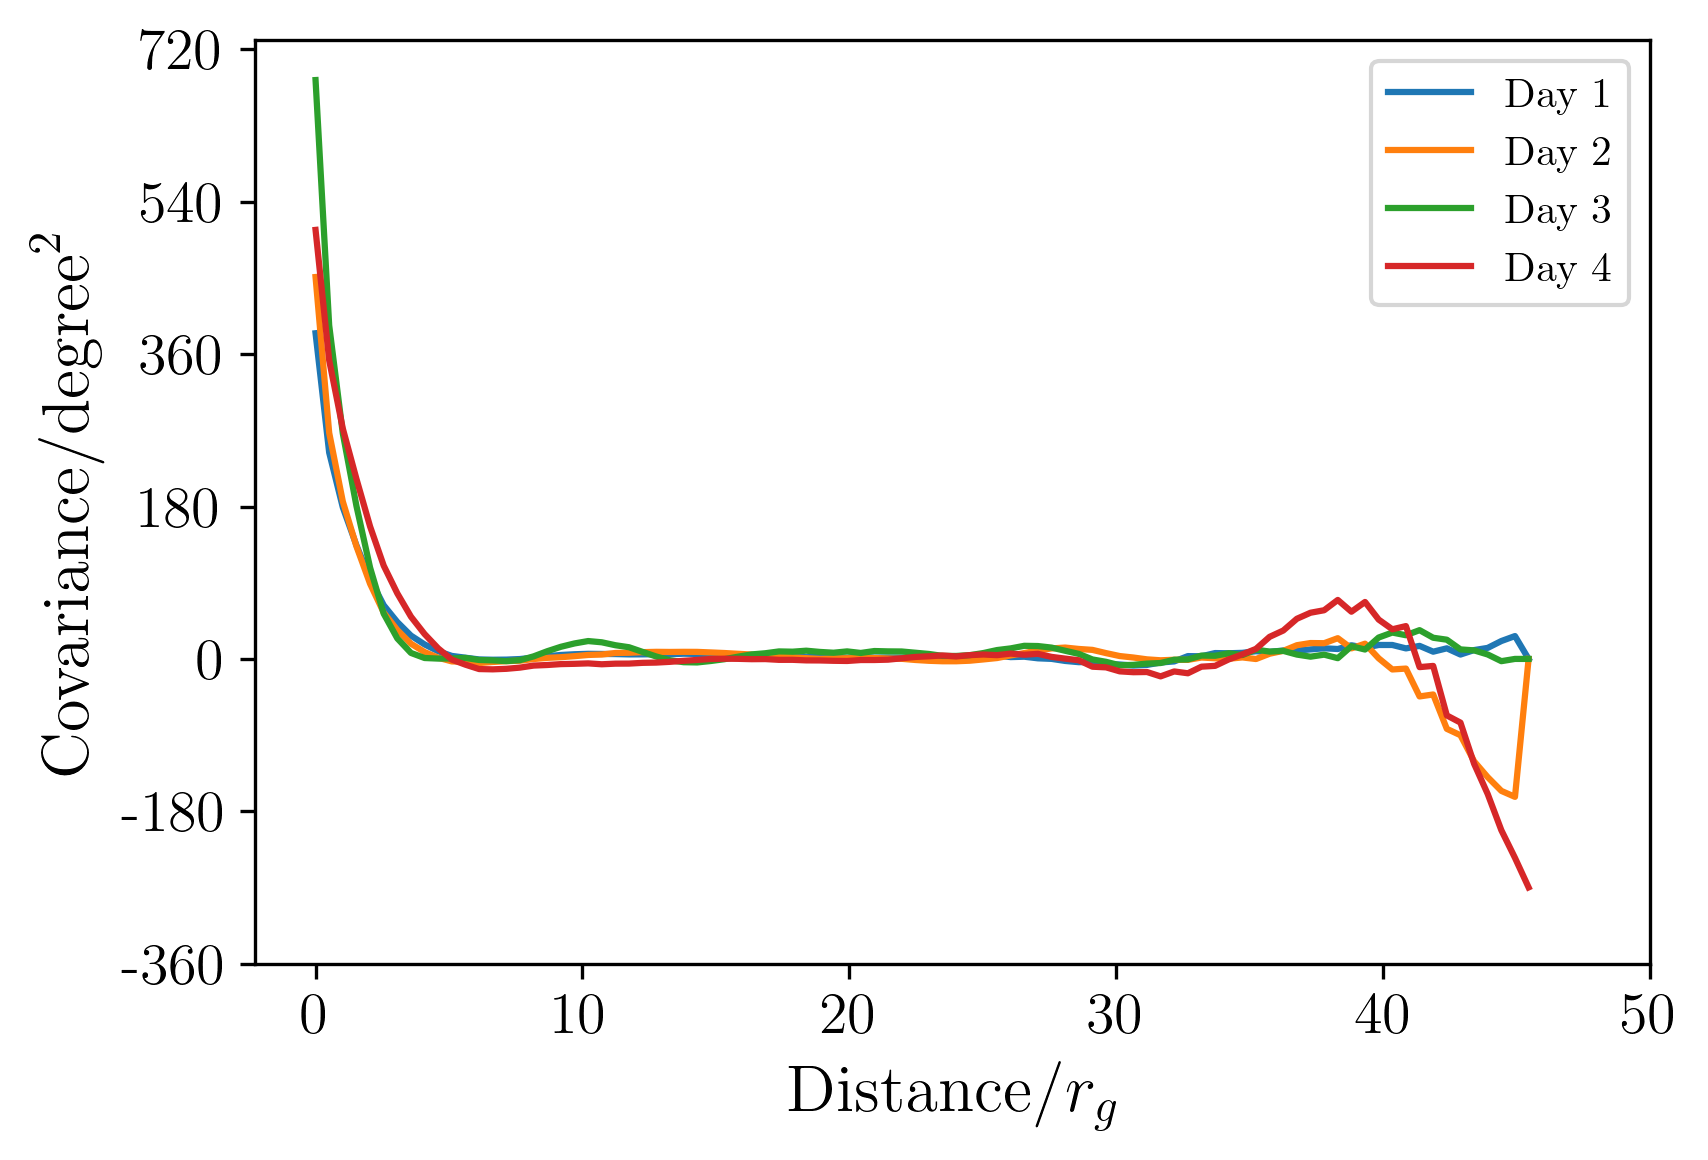

In [ ]:
import numpy as np

# --- Function to compute (distance, covariance) pairs from a 4096×4096 cor matrix ---
rg_per_pixel = 0.51073125


def cor_to_distance_cov_matrix(cor, H=64, W=64):
    """
    Input:
        cor : 4096×4096 covariance matrix (flattened 64×64 grid)
    Output:
        result : shape (2, 4096*4096)
                 result[0] = distances
                 result[1] = covariance values
    """

    N = H * W

    # Build coordinates: (y, x) for each of 4096 points
    coords = np.array([(i, j) for i in range(H) for j in range(W)], dtype=np.float32)

    # Compute pairwise distances (4096×4096)
    diff = coords[:, None, :] - coords[None, :, :]
    dist_mat = np.sqrt((diff**2).sum(axis=2))

    # Flatten
    dist_flat = dist_mat.reshape(-1)
    cor_flat = cor.reshape(-1)

    # Combine into (2, N*N)
    result = np.vstack([dist_flat, cor_flat])
    return result


fig, ax = plt.subplots(figsize=(6, 4), dpi=300)
for day in range(4):
    # result = cor_to_distance_cov_matrix(np.abs(theta_cor[day]))
    result = cor_to_distance_cov_matrix(theta_cor[day])
    dist = result[0]
    cov = result[1]
    dist_int = np.rint(dist).astype(int)
    max_d = dist_int.max()

    sum_cov = np.zeros(max_d + 1, dtype=np.float64)
    count = np.zeros(max_d + 1, dtype=np.int64)

    for d, v in zip(dist_int, cov):
        if np.isfinite(v):
            sum_cov[d] += v
            count[d] += 1

    avg_cov = np.zeros_like(sum_cov)
    mask = count > 0
    avg_cov[mask] = sum_cov[mask] / count[mask]

    # Smoothed result as a 2×N array (distance, avg_cov)
    smoothed = np.vstack([np.arange(max_d + 1), avg_cov])
    ax.plot(smoothed[0], smoothed[1], label=f"Day {day+1}")

label_size = 16  # 控制横纵坐标名字的大小
tick_size = 14  # 控制坐标轴数字的大小
# ax.set_xlim(0, max_d)
ax.set_xticks(np.asarray([0, 10, 20, 30, 40, 50]) / rg_per_pixel)
ax.set_xticklabels(np.asarray([0, 10, 20, 30, 40, 50]))


ax.set_yticks(
    np.asarray([-360, -180, 0, 180, 360, 540, 720]) / 180 / 180 * np.pi * np.pi
)
ax.set_yticklabels(np.asarray([-360, -180, 0, 180, 360, 540, 720]))

ax.set_xlabel("Distance/$r_g$", fontsize=label_size)  # 横坐标名字
ax.set_ylabel("Covariance/$\mathrm{degree}^2$", fontsize=label_size)  # 纵坐标名字

# 设置坐标轴刻度数字的大小
ax.tick_params(axis="both", which="major", labelsize=tick_size)
ax.legend()

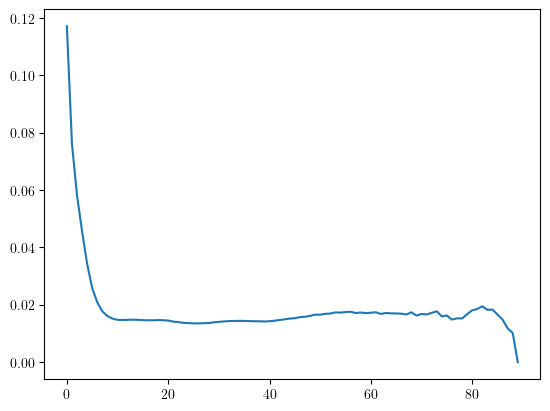